### My Question
##### From a deck of UNO action cards, what is the probability that I draw 4 different action cards (+2/+4, wild, reverse, skip) in a row?

### My Study
Describe your simulation here:
1. The random process being simulated is drawing from a deck of just uno action cards.
2. One trial will look like drawing 4 cards from the modified deck without replacing them. The possible outcomes of this trial include any combination of 4 Uno action cards, including repeats.
4. I'm interested in the event of pulling 4 different action cards without repeats. There are 24 different outcomes for this event, as that is the total number of ways to arrange 4 different types of cards in different orders.
5. Events:
- A: Pulling a take card (+2 or +4)
- B: Pulling a wild card (excluding +4's)
- C: Pulling a reverse card
- D: Pulling a skip card
My question is asking for A and B and C and D, which is a joint probability.
6. A, B, C, and D, are not mutually exclusive because getting one of these events does not eliminate the probability of getting another one of these events on the next try. Also, the probabilities of these events do not add up to 1.
7. Since I am not replacing the card after drawing it, these events are not independent of each other. When I draw one card, I change the probability of drawing any of the other action cards.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [19]:
#find theoretical prob.
#24 different possible outcomes, so add all them together
Prob_ABCD = (12/32)*(4/31)*(8/30)*(8/29)
#oh wait! the denominator's always the same, so we can add the probabilities and divide by (32*31*30*19) at the end
#also, every numerator is the same as well, just in different orders as well, so I can just multiply Prob_ABCD by 24 to account for all outcomes of P(A&B&C&D)
Prob_ABCD *= 24
print(Prob_ABCD)

0.08542825361512793


In [20]:
def plot_action_deck_convergence(num_trials=1000):
    # Construct the modified 32-card action deck ONLY
    deck = np.array(
        ['+2/+4'] * 12 +
        ['Wild']    * 4  +
        ['Reverse'] * 8  +
        ['Skip']    * 8
    )
    target_set = {'+2/+4', 'Wild', 'Reverse', 'Skip'}

    # 1. Binary outcomes array (1 for success, 0 for failure)
    outcomes = np.zeros(num_trials)
    for i in range(num_trials):
        draw = np.random.choice(deck, size=4, replace=False)
        if set(draw) == target_set:
            outcomes[i] = 1

    # 2. Cumulative running probability
    trials = np.arange(1, num_trials + 1)
    cumulative_prob = np.cumsum(outcomes) / trials

    # 3. Theoretical exact probability for action-only deck (32 cards)
    theoretical_prob = Prob_ABCD

    # Print summary
    total_successes = int(np.sum(outcomes))
    final_sim_prob = cumulative_prob[-1]
    print(f"--- Action-Only Deck Simulation Summary ({num_trials:,} trials) ---")
    print(f"Total Cards in Deck : {len(deck)}")
    print(f"Total Successes     : {total_successes}")
    print(f"Final Simulated Prob: {final_sim_prob * 100:.2f}%")
    print(f"Theoretical Prob    : {theoretical_prob * 100:.2f}%")

    # 4. Graphing
    sns.set_theme(style="whitegrid")
    plt.figure(figsize=(10, 5))

    # Plot running cumulative probability
    plt.plot(
        trials, 
        cumulative_prob * 100, 
        color='#2ecc71', 
        linewidth=2, 
        label=f'Simulated Cumulative Prob (Final: {final_sim_prob * 100:.2f}%)'
    )

    # Plot theoretical probability line
    plt.axhline(
        y=theoretical_prob * 100, 
        color='#e74c3c', 
        linestyle='--', 
        linewidth=1.8, 
        label=f'Theoretical Prob ({theoretical_prob * 100:.2f}%)'
    )

    plt.title('Monte Carlo Convergence (32-Card Action Deck): Drawing 4 Distinct Power Cards', fontsize=12, fontweight='bold')
    plt.xlabel('Trial Number', fontsize=11)
    plt.ylabel('Cumulative Probability (%)', fontsize=11)
    plt.legend(loc='upper right', frameon=True)
    plt.tight_layout()
    plt.show()

--- Action-Only Deck Simulation Summary (1,000 trials) ---
Total Cards in Deck : 32
Total Successes     : 95
Final Simulated Prob: 9.50%
Theoretical Prob    : 8.54%


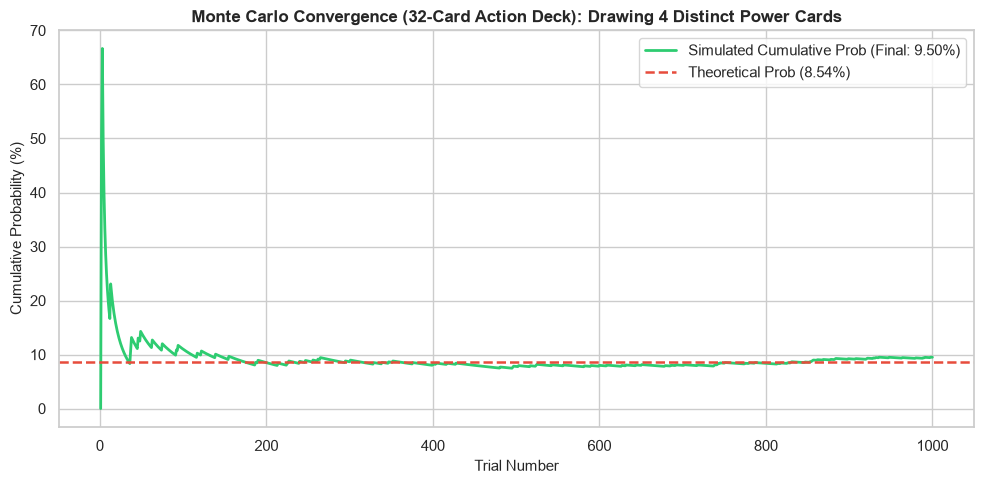

In [21]:
#run simulation
plot_action_deck_convergence(num_trials=1000)

### My Conclusion
1. The empirical probability of drawing 4 different action cards from a deck of UNO action cards from this random simulation was 9.5%. The theoretical probability is 8.54%
2. Graph in above cell
3. The graph shows 1000 trials of drawing 4 cards from the UNO action card deck. As it reaches the end of 1000 trials, the cumulative probability of the simulation of drawing 4 different action cards comes closer and closer to the theoretical probability (the green line reaches the red dashed line). This shows that, after many trials, the probability of drawing four different action cards does indeed reach 8.54%, which is the theoretical calculated probability.